# O que faz um Filme ser um Sucesso?

Você já se perguntou se existe alguma condição em comum entre os filmes que chegam ao topo? Será que o filme mais lucrativo é também o mais amado pelo público? Ou será que o sucesso segue padrões diferentes quando olhamos para dinheiro, tempo e gênero?

Neste projeto, defino sucesso em duas dimensões: **sucesso financeiro**, medido pela receita (`revenue`), e **sucesso de crítica do público**, medido pela nota média (`vote_average`) ponderada pela quantidade de votos (`vote_count`).

O objetivo é investigar, com dados, quais fatores estão associados a essas duas formas de sucesso.

## Base de Dados

Este projeto utiliza a base **TMDB Popular Movies**, disponível no Kaggle em: [TMDB Popular Movies Dataset](https://www.kaggle.com/datasets/thedevastator/exploring-popular-movies-using-tmdb-data?)

A base contém **10.000 filmes**, lançados entre **1890 e 2018**, com **24 idiomas diferentes** e 15 colunas, incluindo receita, avaliação, duração (`runtimes`), gêneros, idioma original, produtora, diretor, elenco e data de lançamento.

**Limitações importantes para a análise:**
- Temos a receita bruta, mas não temos o orçamento (`budget`), então não é possível calcular o lucro real.
- A nota média precisa ser analisada junto com a contagem de votos para evitar distorção de filmes com pouquíssimos votos.
- A receita não está ajustada pela inflação, o que exige cuidado ao comparar filmes de décadas diferentes.

A base também apresenta valores ausentes em colunas como `production_companies`, `genres` e `writer`, que serão tratados na etapa de limpeza.

## Perguntas de Negócio

Para guiar a análise, o projeto foi dividido em 3 perguntas principais:

**P1 - Dinheiro x Qualidade: O filme que lucra mais é o mesmo que é melhor avaliado?**
Investigar se existe correlação entre `revenue` e `vote_average`. Um filme bem avaliado necessariamente arrecada mais?

**P2 - Evolução no Tempo: A indústria está fazendo filmes mais longos ou mais curtos com o tempo?**
Analisar como a duração média dos filmes (`runtimes`) evoluiu ao longo dos anos e décadas.

**P3 - Gênero de Risco: Existe um gênero mais "arriscado"?**
Identificar qual gênero apresenta maior variância nas notas. Ou seja, qual gênero é mais 8 ou 80 - quando acerta, é amado, e quando erra, é muito mal avaliado.

## Ferramentas e Tecnologias

- **Python** com **Pandas** para manipulação e limpeza dos dados
- **Matplotlib e Seaborn** para visualização
- **Jupyter Notebook** para documentação e storytelling

## Estrutura do Projeto

1.  **Entendimento e Limpeza dos Dados:** Conversão de tipos, tratamento de nulos e tratamento de colunas com múltiplos valores.
2.  **Análise Exploratória (EDA):** Resposta às 3 perguntas de negócio com análises e visualizações.
3.  **Conclusões e Próximos Passos:** Insights encontrados e o que poderia ser explorado em uma próxima versão.

Obs: Para a análise de duração, optei por não imputar os 120 valores ausentes (1,2%). Por se tratar da própria variável de estudo e a ausência estar concentrada nos anos 90/2000, a imputação pela mediana reduziria artificialmente a variância. A análise de evolução temporal foi feita desconsiderando os nulos.

In [5]:
import pandas as pd 

In [6]:
import numpy as np
import matplotlib.pyplot as plt

In [7]:
df = pd.read_csv("movies.csv")

In [8]:
df.head()

,index,revenue,vote_average,vote_count,title,original_language,release_date,production_companies,production_countries,genres,director,producer,cast,runtimes,writer
0,0,4300000,6.6,714,Four Rooms,en,1995-12-09,"Miramax Films,A Band Apart",United States of America,"Crime,Comedy","Allison Anders,Alexandre Rockwell,Robert Rodri...","Lawrence Bender,Paul Hellerman,Scott Lambert,","Sammi Davis,Amanda De Cadenet,Valeria Golino,",98.0,"Allison Anders,Alexandre Rockwell,Robert Rodri..."
1,1,12,6.4,96,Judgment Night,en,1993-10-15,"Universal Pictures,Largo Entertainment,JVC Ent...","Japan,United States of America","Action,Thriller,Crime",Stephen Hopkins,"Gene Levy,Christopher Mollo,Lloyd Segan,","Emilio Estevez,Cuba Gooding Jr.,Denis Leary,",110.0,"Lewis Colick,Jere Cunningham,Lewis Colick"
2,2,775398007,8.1,8550,Star Wars,en,1977-05-25,"Lucasfilm,20th Century Fox",United States of America,"Adventure,Action,Science Fiction",George Lucas,"Gary Kurtz,George Lucas,Rick McCallum","Mark Hamill,Harrison Ford,Carrie Fisher,",121.0,George Lucas
3,3,940335536,7.7,8085,Finding Nemo,en,2003-05-30,Pixar,United States of America,"Animation,Family","Andrew Stanton,Lee Unkrich","Jinko Gotoh,John Lasseter,Graham Walters","Albert Brooks,Ellen DeGeneres,Alexander Gould,",100.0,"Andrew Stanton,Andrew Stanton,Bob Peterson,"
4,4,677945399,8.3,10346,Forrest Gump,en,1994-07-06,Paramount,United States of America,"Comedy,Drama,Romance",Robert Zemeckis,"Wendy Finerman,Charles Newirth,Steve Starkey,","Tom Hanks,Rebecca Williams,Sally Field,",142.0,"Winston Groom,Eric Roth"


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   index                 10000 non-null  int64  
 1   revenue               10000 non-null  int64  
 2   vote_average          10000 non-null  float64
 3   vote_count            10000 non-null  int64  
 4   title                 10000 non-null  object 
 5   original_language     10000 non-null  object 
 6   release_date          9992 non-null   object 
 7   production_companies  8515 non-null   object 
 8   production_countries  10000 non-null  object 
 9   genres                9757 non-null   object 
 10  director              9931 non-null   object 
 11  producer              9885 non-null   object 
 12  cast                  9968 non-null   object 
 13  runtimes              9880 non-null   float64
 14  writer                9710 non-null   object 
dtypes: float64(2), int64

In [10]:
print(f"Shape original: {df.shape}")
print(f"Duplicatas: {df.duplicated().sum()}")
print(df.isna().sum().sort_values(ascending=False))

Shape original: (10000, 15)
Duplicatas: 0
production_companies    1485
writer                   290
genres                   243
runtimes                 120
producer                 115
director                  69
cast                      32
release_date               8
index                      0
revenue                    0
vote_average               0
vote_count                 0
title                      0
original_language          0
production_countries       0
dtype: int64


Limitação de dados: 6.337 filmes (63,3%) apresentam revenue = 0, interpretado como ausência de informação de bilheteria e não como bilheteria nula. Por isso, a análise de correlação entre receita e qualidade (P1) foi restrita aos 3.663 filmes com receita > 0 e mais de 100 votos.

In [11]:
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')

In [12]:
df['release_year'] = df['release_date'].dt.year

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   index                 10000 non-null  int64         
 1   revenue               10000 non-null  int64         
 2   vote_average          10000 non-null  float64       
 3   vote_count            10000 non-null  int64         
 4   title                 10000 non-null  object        
 5   original_language     10000 non-null  object        
 6   release_date          9992 non-null   datetime64[ns]
 7   production_companies  8515 non-null   object        
 8   production_countries  10000 non-null  object        
 9   genres                9757 non-null   object        
 10  director              9931 non-null   object        
 11  producer              9885 non-null   object        
 12  cast                  9968 non-null   object        
 13  runtimes         

In [14]:
df['runtimes'] = df['runtimes'].astype('Int64')

In [15]:
print("\n--- Após conversão ---")
print(df[['release_date', 'release_year', 'runtimes']].info())
print(df[['release_date', 'release_year', 'runtimes']].isna().sum())


--- Após conversão ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   release_date  9992 non-null   datetime64[ns]
 1   release_year  9992 non-null   float64       
 2   runtimes      9880 non-null   Int64         
dtypes: Int64(1), datetime64[ns](1), float64(1)
memory usage: 244.3 KB
None
release_date      8
release_year      8
runtimes        120
dtype: int64


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   index                 10000 non-null  int64         
 1   revenue               10000 non-null  int64         
 2   vote_average          10000 non-null  float64       
 3   vote_count            10000 non-null  int64         
 4   title                 10000 non-null  object        
 5   original_language     10000 non-null  object        
 6   release_date          9992 non-null   datetime64[ns]
 7   production_companies  8515 non-null   object        
 8   production_countries  10000 non-null  object        
 9   genres                9757 non-null   object        
 10  director              9931 non-null   object        
 11  producer              9885 non-null   object        
 12  cast                  9968 non-null   object        
 13  runtimes         

In [17]:
df['release_year'] = df['release_year'].astype('Int64')

## 2. Qualidade dos Dados e Decisões de Limpeza

A base contém 10.000 filmes com 15 colunas. Não foram encontradas linhas duplicadas. A análise de completude revelou pontos importantes para as perguntas de negócio:

| Coluna | Faltantes | % | Decisão | Justificativa |
|---|---|---|---|---|
| **revenue** | 6.337 | 63,3% | Filtrar apenas `revenue > 0` para P1 | Valor 0 não representa bilheteria nula, e sim ausência de informação no TMDB. Incluir distorceria a correlação e quebraria a transformação logarítmica. |
| **production_companies** | 1.485 | 14,8% | Manter como NA | Ausência não impacta as 3 perguntas principais. |
| **genres** | 243 | 2,4% | Manter e desconsiderar no explode | Perda pequena, não justifica imputação. |
| **runtimes** | 120 | 1,2% | Não imputar, manter como `<NA>` | Por se tratar da própria variável de estudo da P2 e a ausência estar concentrada nos anos 90/2000, a imputação pela mediana reduziria artificialmente a variância. Análise temporal feita com `dropna`. |
| **release_date** | 8 | 0,08% | Converter para datetime com `errors='coerce'` | 8 datas inválidas viraram `NaT`. Criação de `release_year` como `Int64` nullable. |

**Impacto nas análises:**
- **P1 (Receita x Qualidade):** Realizada com subconjunto de 3.663 filmes com receita válida e `vote_count > 100` para garantir notas confiáveis.
- **P2 (Evolução da duração):** Realizada desconsiderando nulos de duração e ano.
- **P3 (Gênero arriscado):** Realizada com 9.757 filmes com gênero válido, explodidos em 23.646 registros de gênero.

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   index                 10000 non-null  int64         
 1   revenue               10000 non-null  int64         
 2   vote_average          10000 non-null  float64       
 3   vote_count            10000 non-null  int64         
 4   title                 10000 non-null  object        
 5   original_language     10000 non-null  object        
 6   release_date          9992 non-null   datetime64[ns]
 7   production_companies  8515 non-null   object        
 8   production_countries  10000 non-null  object        
 9   genres                9757 non-null   object        
 10  director              9931 non-null   object        
 11  producer              9885 non-null   object        
 12  cast                  9968 non-null   object        
 13  runtimes         

### P1: Filmes com maior bilheteria são melhor avaliados?

<Axes: xlabel='vote_average', ylabel='revenue'>

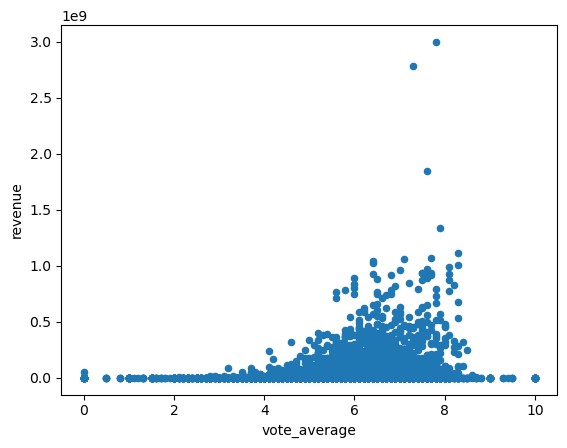

In [23]:
df.plot.scatter(y='revenue', x='vote_average')

<Axes: >

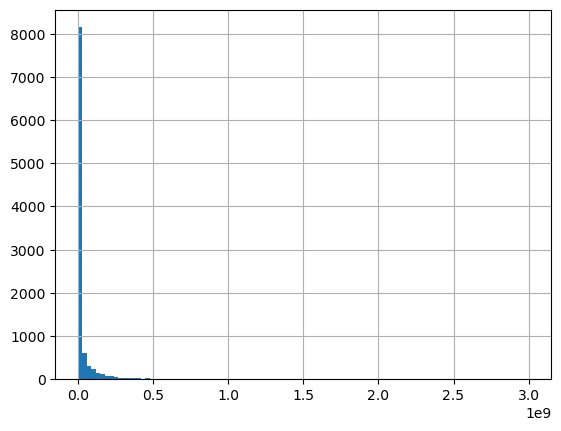

In [24]:
df['revenue'].hist(bins=100)

In [25]:
filtrado = df[(df['revenue'] > 0) & (df['vote_count'] > 100)].copy()

In [26]:
filtrado['log_revenue'] = np.log10(filtrado['revenue'])

In [27]:
filtrado[['log_revenue','vote_average']].corr()

,log_revenue,vote_average
log_revenue,1.00000,0.05873
vote_average,0.05873,1.00000


<Axes: xlabel='log_revenue', ylabel='vote_average'>

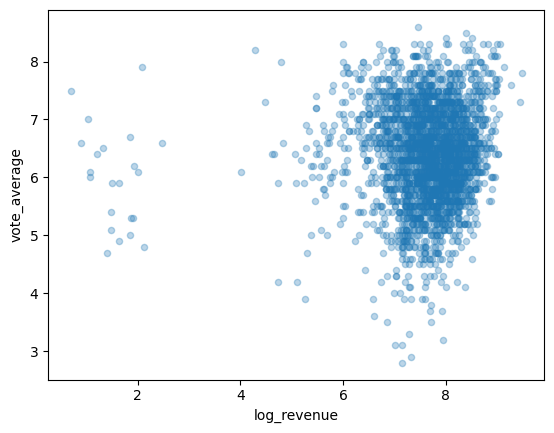

In [28]:
filtrado.plot.scatter(x='log_revenue', y='vote_average', alpha=0.3)

### P1: **Resposta: Não. Correlação praticamente nula (0,05) - dinheiro não compra nota.**


Após identificar que 6.337 filmes (63,3%) possuem revenue = 0 interpretado como dado faltante, a análise foi restrita a 3.663 filmes com bilheteria válida e `vote_count > 100`.

Devido à forte assimetria da receita (de $12 a $900M), foi aplicada transformação `log10(revenue)` para visualização. A correlação de Pearson entre log da receita e `vote_average` foi de 0,058, indicando ausência de relação linear.

O scatter plot confirma: há blockbusters de 100M com nota 4 e filmes de 1M com nota 8. A qualidade percebida não é explicada pelo tamanho da bilheteria.

### P2: A duração dos filmes está aumentando com o tempo?

In [29]:
df_time = df.dropna(subset=['release_year','runtimes'])

In [30]:
evolucao = df_time.groupby('release_year')['runtimes'].mean()

<Axes: xlabel='release_year'>

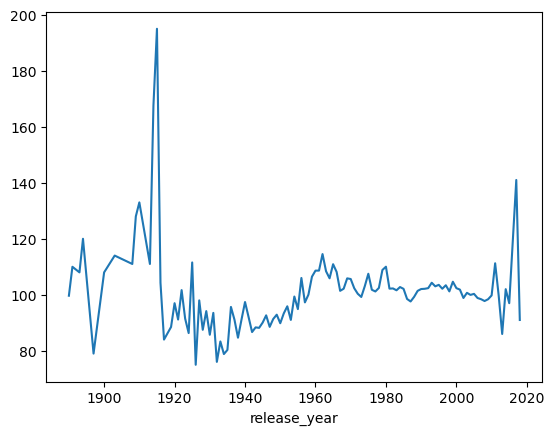

In [31]:
evolucao.plot()

In [35]:
df_time = df.dropna(subset=['release_year','runtimes']).copy()

df_time['decade'] = (df_time['release_year']//10*10).astype(int)

In [36]:
evolucao_decada = df_time.groupby('decade')['runtimes'].mean()

Text(0.5, 1.0, 'Duração média por década - estável em torno de 100min')

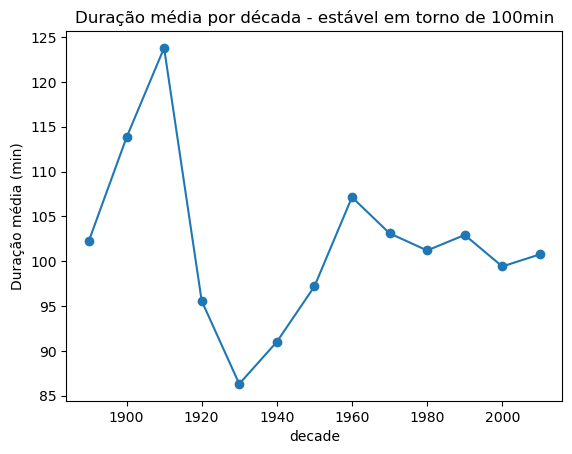

In [37]:
evolucao_decada.plot(marker='o')
plt.ylabel('Duração média (min)')
plt.title('Duração média por década - estável em torno de 100min')

### P2: **Resposta: Não. A duração é estável em torno de 100 min.**


Após remover os 120 nulos de `runtimes`, analisei a média anual. A média geral é de 100,3 min. 
Observa-se um pico na década de 60 (107,1 min - era dos filmes épicos) e estabilidade nas últimas 4 décadas entre 99 e 102 minutos.

Essa estabilidade contraria a percepção de que filmes atuais são mais longos.

### P3: Existe um gênero arriscado que ou é muito bom ou muito ruim?

In [19]:
df_genres = df.assign(single_genre = df['genres'].str.split(',')).explode('single_genre')

In [20]:
df_genres['single_genre'] = df_genres['single_genre'].str.strip()

In [21]:
stats_genero = df_genres.groupby('single_genre')['vote_average'].agg(['mean','std','count']).sort_values('std', ascending=False)

In [22]:
stats_genero.head(10)

,mean,std,count
single_genre,,,
Documentary,5.681516,2.472783,541
Music,5.984708,1.900373,497
TV Movie,5.295181,1.712408,166
Horror,4.876478,1.655727,1522
Family,5.724790,1.591590,952
Western,5.858182,1.581103,275
Science Fiction,5.301622,1.545745,1048
Thriller,5.648044,1.406531,2377
Comedy,5.738714,1.398561,3407


### P3: **Resposta: Sim. Documentary é o gênero mais polarizado e arriscado.**


A base possui 10.000 filmes com 243 gêneros faltantes. Após `split(',')` e `explode()`, foram gerados 23.646 registros de gênero. Calculado desvio padrão da nota por gênero:

- **Documentary:** média 5,68 / **std 2,47** / n=541
- **Music:** média 5,98 / std 1,90 / n=497  
- **Horror:** média 4,87 / std 1,65 / n=1.522
- **Action:** média 5,57 / std 1,37 / n=2.029 (mais consistente)
- **Comedy:** média 5,73 / std 1,39 / n=3.407 (mais consistente)

Documentary apresenta desvio 80% maior que Action. Indica alta polarização: existem documentários aclamados nota 9 e outros com nota 2 na mesma categoria. Gêneros populares como Action e Comedy são mais "seguros", com notas concentradas entre 5 e 7.